# Week 11 - Introduction to Modeling, part 2

# 1. Lesson - No lesson this week

# 2. Weekly graph question

In [13]:
%pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [14]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

The book names one of Vonnegut's rules as "keep it simple" and another as "have the guts to cut."  Here is some data from the previous week's lesson.  If you had to cut one of the two plots below, which would it be?  Which seems more interesting or important?  Explain.  (Should "amount of training data used" or "number of estimators" be on the x-axis.)

In [ ]:
np.random.seed(0)
num_points = 10000
feature_1a = np.random.random(size = num_points) * 3
feature_2a = np.random.random(size = num_points) * 3
feature_3a = np.random.random(size = num_points) * 3
train_target = (feature_1a - 2 * feature_2a) * feature_3a + np.random.normal(size = num_points)
feature_1b = np.random.random(size = num_points) * 3
feature_2b = np.random.random(size = num_points) * 3
feature_3b = np.random.random(size = num_points) * 3
test_target = (feature_1b - 2 * feature_2b) * feature_3b + np.random.normal(size = num_points)
train_df = pd.DataFrame({"f1": feature_1a, "f2": feature_2a, "f3": feature_3a})
test_df = pd.DataFrame({"f1": feature_1b, "f2": feature_2b, "f3": feature_3b})
rf = RandomForestRegressor()
rf.fit(train_df.values, train_target)

In [ ]:
rmse_lst = list()
rf = RandomForestRegressor()
for x in range(round(num_points / 20), num_points, round(num_points / 20)):
    rf.fit(train_df.values[0:x,:], train_target[0:x])
    rmse_lst.append(root_mean_squared_error(rf.predict(test_df.values), test_target))

import matplotlib.pyplot as plt

Text(0, 0.5, 'Loss function')

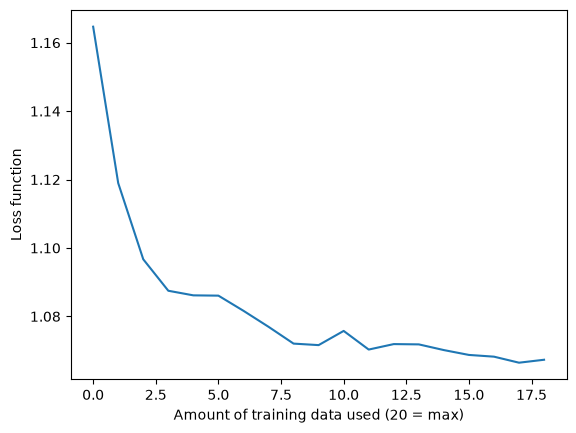

In [ ]:
plt.plot(rmse_lst)
plt.xlabel("Amount of training data used (20 = max)")
plt.ylabel("Loss function")

In [ ]:
num_trees_lst = list()
for n_estimators in range(1, 100, 3):
    rf = RandomForestRegressor(n_estimators = n_estimators)
    rf.fit(train_df.values, train_target)
    num_trees_lst.append(root_mean_squared_error(rf.predict(test_df.values), test_target))

Text(0, 0.5, 'Loss function')

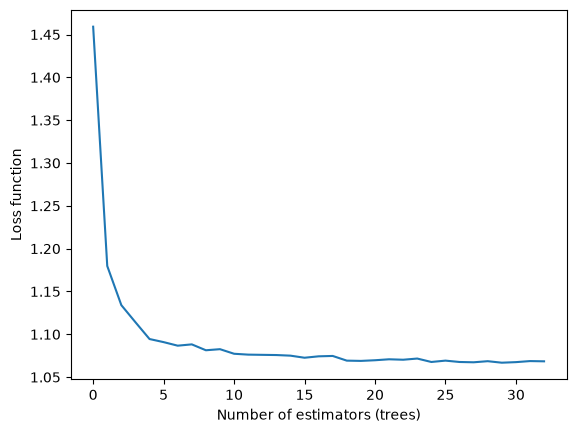

In [ ]:
plt.plot(num_trees_lst)
plt.xlabel("Number of estimators (trees)")
plt.ylabel("Loss function")

If I had to cut one plot, I would cut the **"number of estimators"** plot and keep **"amount of training data used."**

Both curves flatten out, but the number-of-trees plot is less useful because it flattens very quickly. The error drops sharply from 1 tree to about 10 trees (roughly 1.5 down to 1.1), and after about 30 trees it stays almost constant near 1.07. This only tells me that a moderate number of trees is enough, and more trees cost computing time without helping. That is a small tuning detail.

The training-data plot is more important because it shows how much data the model needs. The error is highest when the model has only a small amount of data (about 1.17) and decreases as more data is added, but the improvement is small after about half of the data. This tells me whether collecting more data would help, which is a more important decision. It also matches the lesson that a model needs enough data to generalize to new data.

Following Vonnegut's "have the guts to cut," I would keep the plot that gives the more important message, so the x-axis should be **amount of training data used**.

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

Here are some types of analysis you can do:

* Implement a random forest model.
* Perform cross-validation.
* Tune hyperparameters.
* Evaluate a performance metric.

If you like, you can try other types of models, too (beyond linear regression and random forest) although you will have many opportunities to do that next semester.

In [ ]:
# Prepare Life Expectancy data for Random Forest

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

# Load dataset
df = pd.read_csv("Life Expectancy Data.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Remove rows with missing values
df = df.dropna()

# Separate predictors and target
X = df.drop(columns=["Life expectancy", "Country"])
X = pd.get_dummies(X, drop_first=True)

y = df["Life expectancy"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Random Forest model
rf = RandomForestRegressor(random_state=42)

# Tune hyperparameters
param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Best model
best_model = grid_search.best_estimator_

# Evaluate model
predictions = best_model.predict(X_test)
rmse = root_mean_squared_error(y_test, predictions)

print("Best parameters:", grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)
print("Final Test RMSE:", rmse)

Best parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}
Best CV RMSE: 1.8419481098380157
Final Test RMSE: 1.892312210010763


**Random Forest on the Life Expectancy data**

I removed the rows with missing values, dropped Country, converted the categorical variable (Status) to numbers with one-hot encoding, and split the data 80% for training and 20% for testing. I then used GridSearchCV with 5-fold cross-validation to tune three hyperparameters (n_estimators: 50, 100, 150; max_depth: None, 10, 20; min_samples_split: 2, 5), which gives 18 combinations. The score was RMSE.

**Results:** The best settings were n_estimators = 150, max_depth = 20, and min_samples_split = 2. The best cross-validation RMSE was about **1.84 years**, and the RMSE on the separate test set was about **1.89 years**. The two values are close, so the model performs consistently on new data and does not appear to be overfitting. On average, its predictions are off by about 1.9 years.

**Limitations:** Removing every row with a missing value reduces the amount of data. Also, each country appears in several years, so rows from the same country can be in both the training and the test data, which may make the error look better than it would for a new country. Next time I would compare this with imputation and with splitting the data by country.

                            Feature  Importance
17  Income composition of resources    0.601284
12                         HIV/AIDS    0.187951
1                   Adult Mortality    0.123692
15             thinness  1-19 years    0.014412
18                        Schooling    0.009631
10                Total expenditure    0.009342
16               thinness 5-9 years    0.009291
3                           Alcohol    0.007960
0                              Year    0.005498
7                               BMI    0.004940


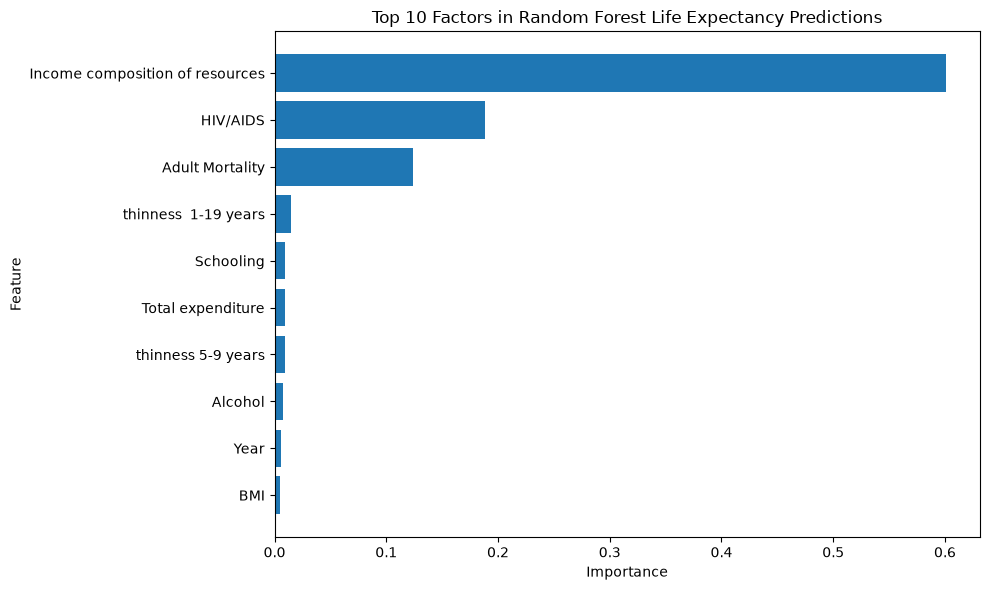

In [ ]:
# Feature Importance

importance = best_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print(feature_importance.head(10))

# Create bar chart
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"].head(10),
    feature_importance["Importance"].head(10)
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Factors in Random Forest Life Expectancy Predictions")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

The feature importance chart shows which variables the Random Forest relied on most. **Income composition of resources** is by far the most important (about 0.60), followed by **HIV/AIDS** (about 0.19) and **Adult Mortality** (about 0.12). Together these three account for about 91% of the total importance. All the other variables are small (about 0.01 or less each).

Schooling has a strong correlation with life expectancy, but its importance here is only about 0.01. This is probably because schooling is closely related to income composition of resources, so the model gets most of the same information from that one variable. This shows why correlation and feature importance can tell different stories. Feature importance shows how useful a variable was to this model, not that it causes changes in life expectancy.

# 4. Storytelling With Data plot

Reproduce any graph of your choice in chapter seven (p. 165-185) of the Storytelling With Data book as best you can. You do not have to get the exact data values right, just the overall look and feel.

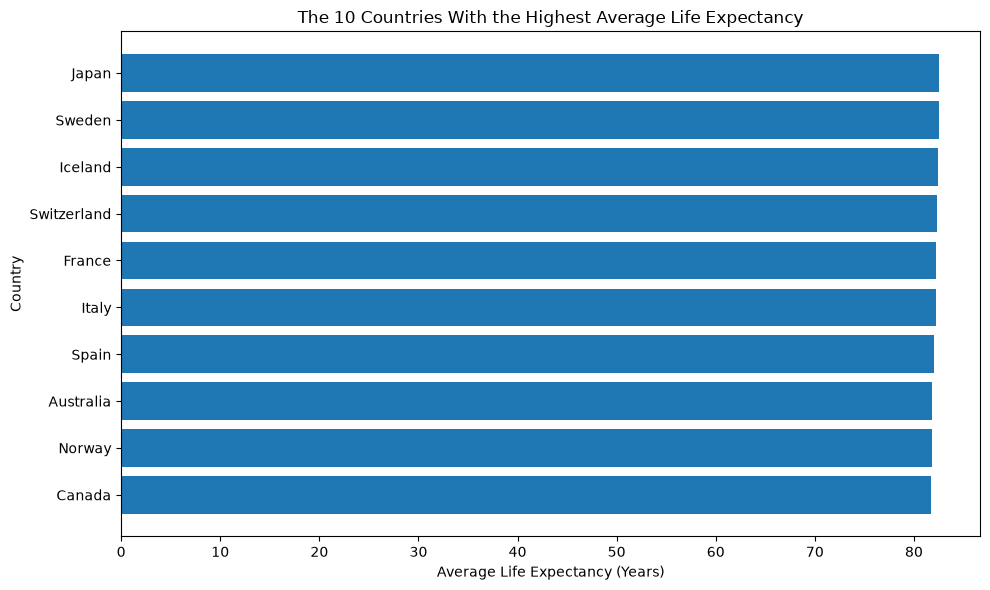

In [ ]:
# 4. Storytelling With Data Plot

import pandas as pd
import matplotlib.pyplot as plt

# Load the Life Expectancy dataset
df = pd.read_csv("Life Expectancy Data.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Calculate average life expectancy for each country
country_life = df.groupby("Country")["Life expectancy"].mean()

# Select the top 10 countries
top_10_countries = country_life.sort_values(
    ascending=False
).head(10)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_countries.index,
    top_10_countries.values
)

plt.xlabel("Average Life Expectancy (Years)")
plt.ylabel("Country")
plt.title("The 10 Countries With the Highest Average Life Expectancy")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

For this assignment, I created a horizontal bar chart inspired by the principles of Storytelling with Data. The chart displays the ten most important variables identified by my Random Forest model when predicting Life Expectancy.

I chose a horizontal bar chart because it makes it easier to compare the importance of different factors. I used a clear title, descriptive labels, and removed unnecessary chart borders to reduce visual clutter.

The main purpose of this visualization is to communicate which variables the model relied on most when making predictions. It also demonstrates how data visualization can make machine learning results easier to understand.